<a href="https://colab.research.google.com/github/Liex2810/lesioscan-ml/blob/main/notebooks/01_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LesioScan — Exploratory Data Analysis (EDA)
Notebook Google Colab. Jalankan setelah PAD-UFES-20 sudah diekstrak ke `data/images` dan metadata ke `data/metadata.csv`. Analisis menyeluruh adalah deskriptif; keputusan model dan preprocessing hanya boleh menggunakan **train set** setelah split.

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
%cd /content/drive/MyDrive/LesioScan-AI
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
ROOT=Path('/content/drive/MyDrive/LesioScan-AI')
DATA=ROOT/'datasets/'
df=pd.read_csv(DATA/'PAD-UFES-20/metadata.csv')
print('Rows',len(df),'Unique patients',df['patient_id'].nunique(),'Unique images',df['img_id'].nunique())
df

/content/drive/MyDrive/LesioScan-AI
Rows 2298 Unique patients 1373 Unique images 2298


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2293,PAT_1708,3156,NaN,NaN,NaN,NaN,73,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1708_3156_175.png,False
2294,PAT_46,880,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,12.0,BCC,True,True,False,True,False,False,PAT_46_880_140.png,True
2295,PAT_1343,1217,NaN,NaN,NaN,NaN,74,NaN,NaN,NaN,...,NaN,SEK,False,False,False,False,False,False,PAT_1343_1217_404.png,False
2296,PAT_326,690,False,False,POMERANIA,POMERANIA,58,True,FEMALE,True,...,4.0,BCC,True,False,False,False,False,True,PAT_326_690_823.png,True


## 1. Pemeriksaan kelengkapan data

In [16]:
from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20"
)

print("Dataset tersedia:", DATASET_DIR.exists())

Dataset tersedia: True


In [17]:
from pathlib import Path

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}

image_paths = {}

for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        if path.name in image_paths:
            raise ValueError(
                f"Nama gambar duplikat: {path.name}"
            )

        image_paths[path.name] = path

print("Total gambar ditemukan:", len(image_paths))

for name, path in list(image_paths.items())[:5]:
    print(name, "->", path)

Total gambar ditemukan: 2298
PAT_100_393_595.png -> /content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20/imgs_part_1/PAT_100_393_595.png
PAT_100_393_898.png -> /content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20/imgs_part_1/PAT_100_393_898.png
PAT_101_1041_651.png -> /content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20/imgs_part_1/PAT_101_1041_651.png
PAT_101_1041_658.png -> /content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20/imgs_part_1/PAT_101_1041_658.png
PAT_101_1041_898.png -> /content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20/imgs_part_1/PAT_101_1041_898.png


In [18]:
display(df.isna().sum().to_frame('nilai_kosong'))
print('Duplikasi img_id:',df['img_id'].duplicated().sum())
missing = df[
    ~df["img_id"].astype(str).isin(image_paths)
]

print("Total metadata:", len(df))
print("Duplikasi img_id:", df["img_id"].duplicated().sum())
print("File gambar hilang:", len(missing))

display(missing.head())
print('File gambar hilang:',len(missing));display(missing.head())

,nilai_kosong
patient_id,0
lesion_id,0
smoke,804
drink,804
background_father,818
background_mother,822
age,0
pesticide,804
gender,804
skin_cancer_history,804


Duplikasi img_id: 0
Total metadata: 2298
Duplikasi img_id: 0
File gambar hilang: 0


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed


File gambar hilang: 0


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed


In [19]:
print("Gambar yang tidak ditemukan:")

display(
    missing[
        ["patient_id", "lesion_id", "img_id", "diagnostic"]
    ]
)

Gambar yang tidak ditemukan:


,patient_id,lesion_id,img_id,diagnostic


## 5. EDA
Menjalankan script membuat CSV/grafik di `outputs/eda`.

,gambar
diagnostic,
ACK,730
BCC,845
MEL,52
NEV,244
SCC,192
SEK,235


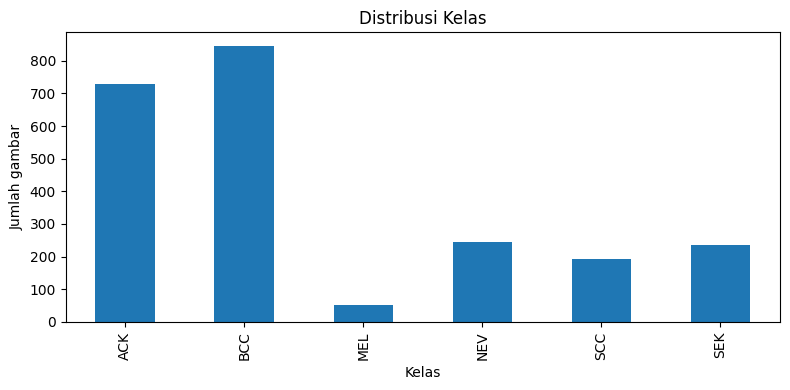

In [20]:
counts=df['diagnostic'].value_counts().sort_index()
display(counts.to_frame('gambar'))
ax=counts.plot.bar(figsize=(8,4),title='Distribusi Kelas')
ax.set(xlabel='Kelas',ylabel='Jumlah gambar');plt.tight_layout();plt.show()

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Distribusi kelas dari metadata
counts = df["diagnostic"].value_counts().sort_values(ascending=False)

total = counts.sum()
percentages = counts / total * 100

# Folder output
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/LesioScan-AI/experiments/eda/figures"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Total gambar:", total)
display(
    pd.DataFrame({
        "Jumlah": counts,
        "Persentase (%)": percentages.round(2)
    })
)

Total gambar: 2298


,Jumlah,Persentase (%)
diagnostic,,
BCC,845,36.77
ACK,730,31.77
NEV,244,10.62
SEK,235,10.23
SCC,192,8.36
MEL,52,2.26


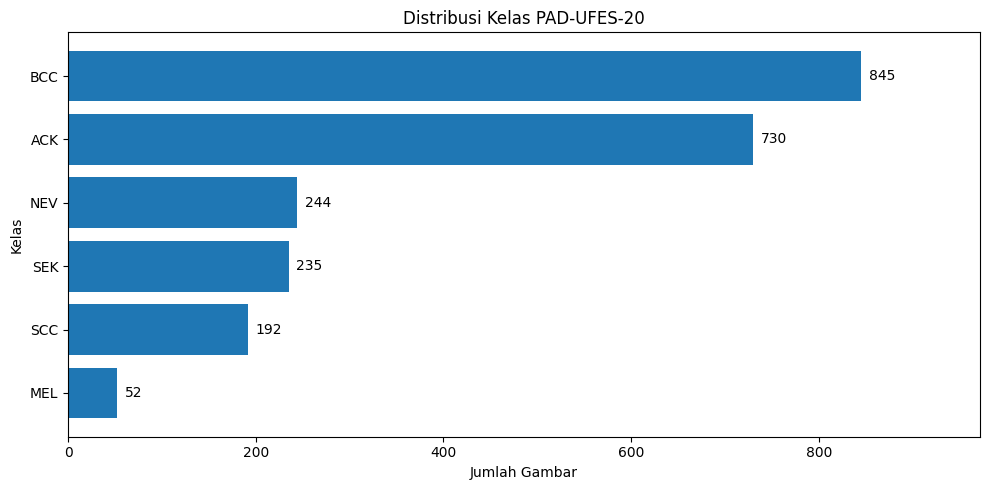

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(counts.index, counts.values)

ax.invert_yaxis()

for bar in bars:
    ax.text(
        bar.get_width() + 8,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center"
    )

ax.set_title("Distribusi Kelas PAD-UFES-20")
ax.set_xlabel("Jumlah Gambar")
ax.set_ylabel("Kelas")
ax.set_xlim(0, counts.max() * 1.15)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution_horizontal.png", dpi=200)
plt.show()

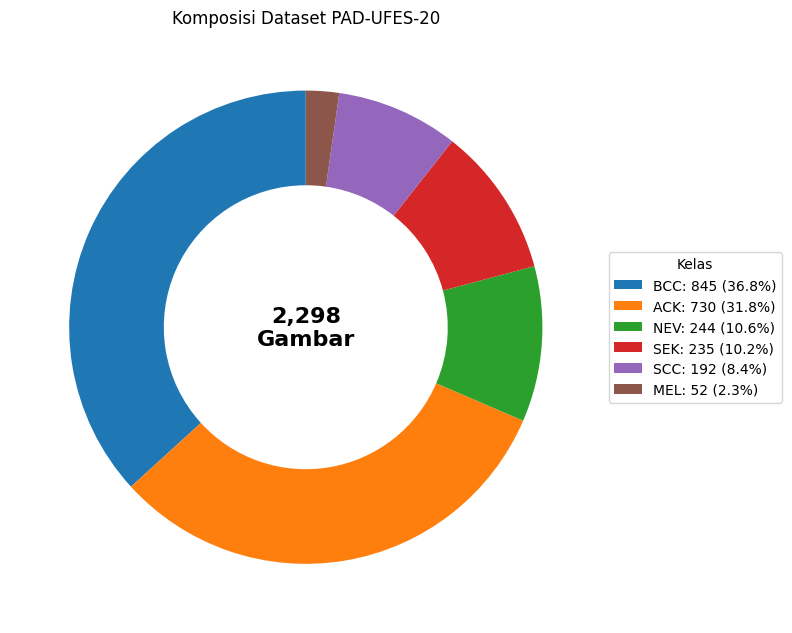

In [25]:
fig, ax = plt.subplots(figsize=(8, 8))

wedges, _ = ax.pie(
    counts.values,
    startangle=90,
    wedgeprops={"width": 0.4}
)

ax.legend(
    wedges,
    [
        f"{kelas}: {jumlah} ({jumlah / total * 100:.1f}%)"
        for kelas, jumlah in counts.items()
    ],
    title="Kelas",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.text(
    0, 0,
    f"{total:,}\nGambar",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

ax.set_title("Komposisi Dataset PAD-UFES-20")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution_donut.png", dpi=200)
plt.show()

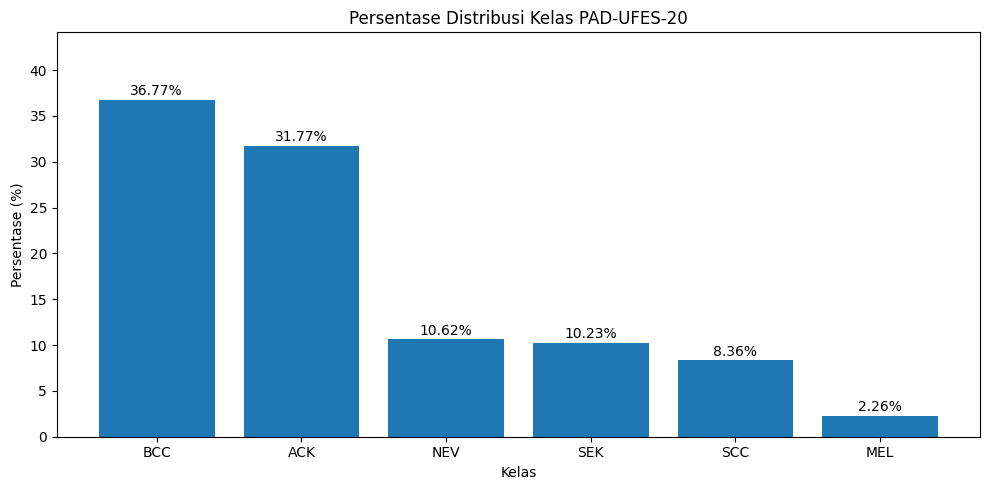

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    percentages.index,
    percentages.values
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

ax.set_title("Persentase Distribusi Kelas PAD-UFES-20")
ax.set_xlabel("Kelas")
ax.set_ylabel("Persentase (%)")
ax.set_ylim(0, percentages.max() * 1.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution_percentage.png", dpi=200)
plt.show()

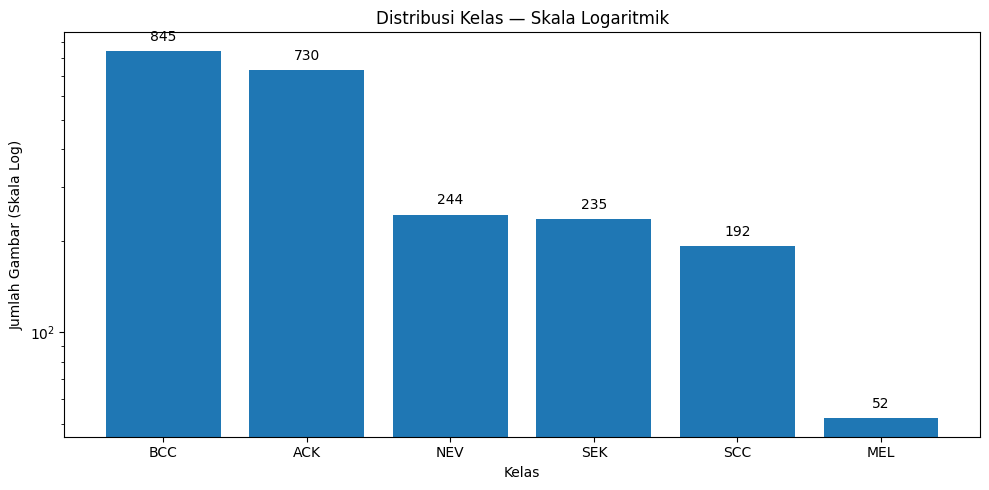

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    counts.index,
    counts.values
)

ax.set_yscale("log")

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 1.08,
        f"{int(bar.get_height())}",
        ha="center"
    )

ax.set_title("Distribusi Kelas — Skala Logaritmik")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah Gambar (Skala Log)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution_log.png", dpi=200)
plt.show()

,gambar_per_pasien
count,1373.000000
mean,1.673707
std,1.115038
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,10.000000


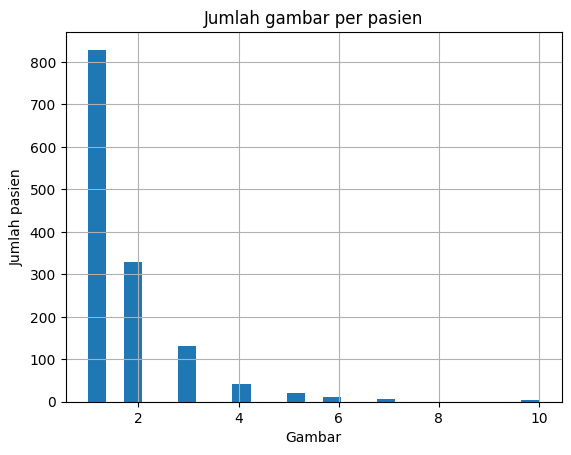

In [21]:
patient_counts=df.groupby('patient_id').size()
display(patient_counts.describe().to_frame('gambar_per_pasien'))
patient_counts.hist(bins=25);plt.title('Jumlah gambar per pasien');plt.xlabel('Gambar');plt.ylabel('Jumlah pasien');plt.show()

Total gambar ditemukan: 2298


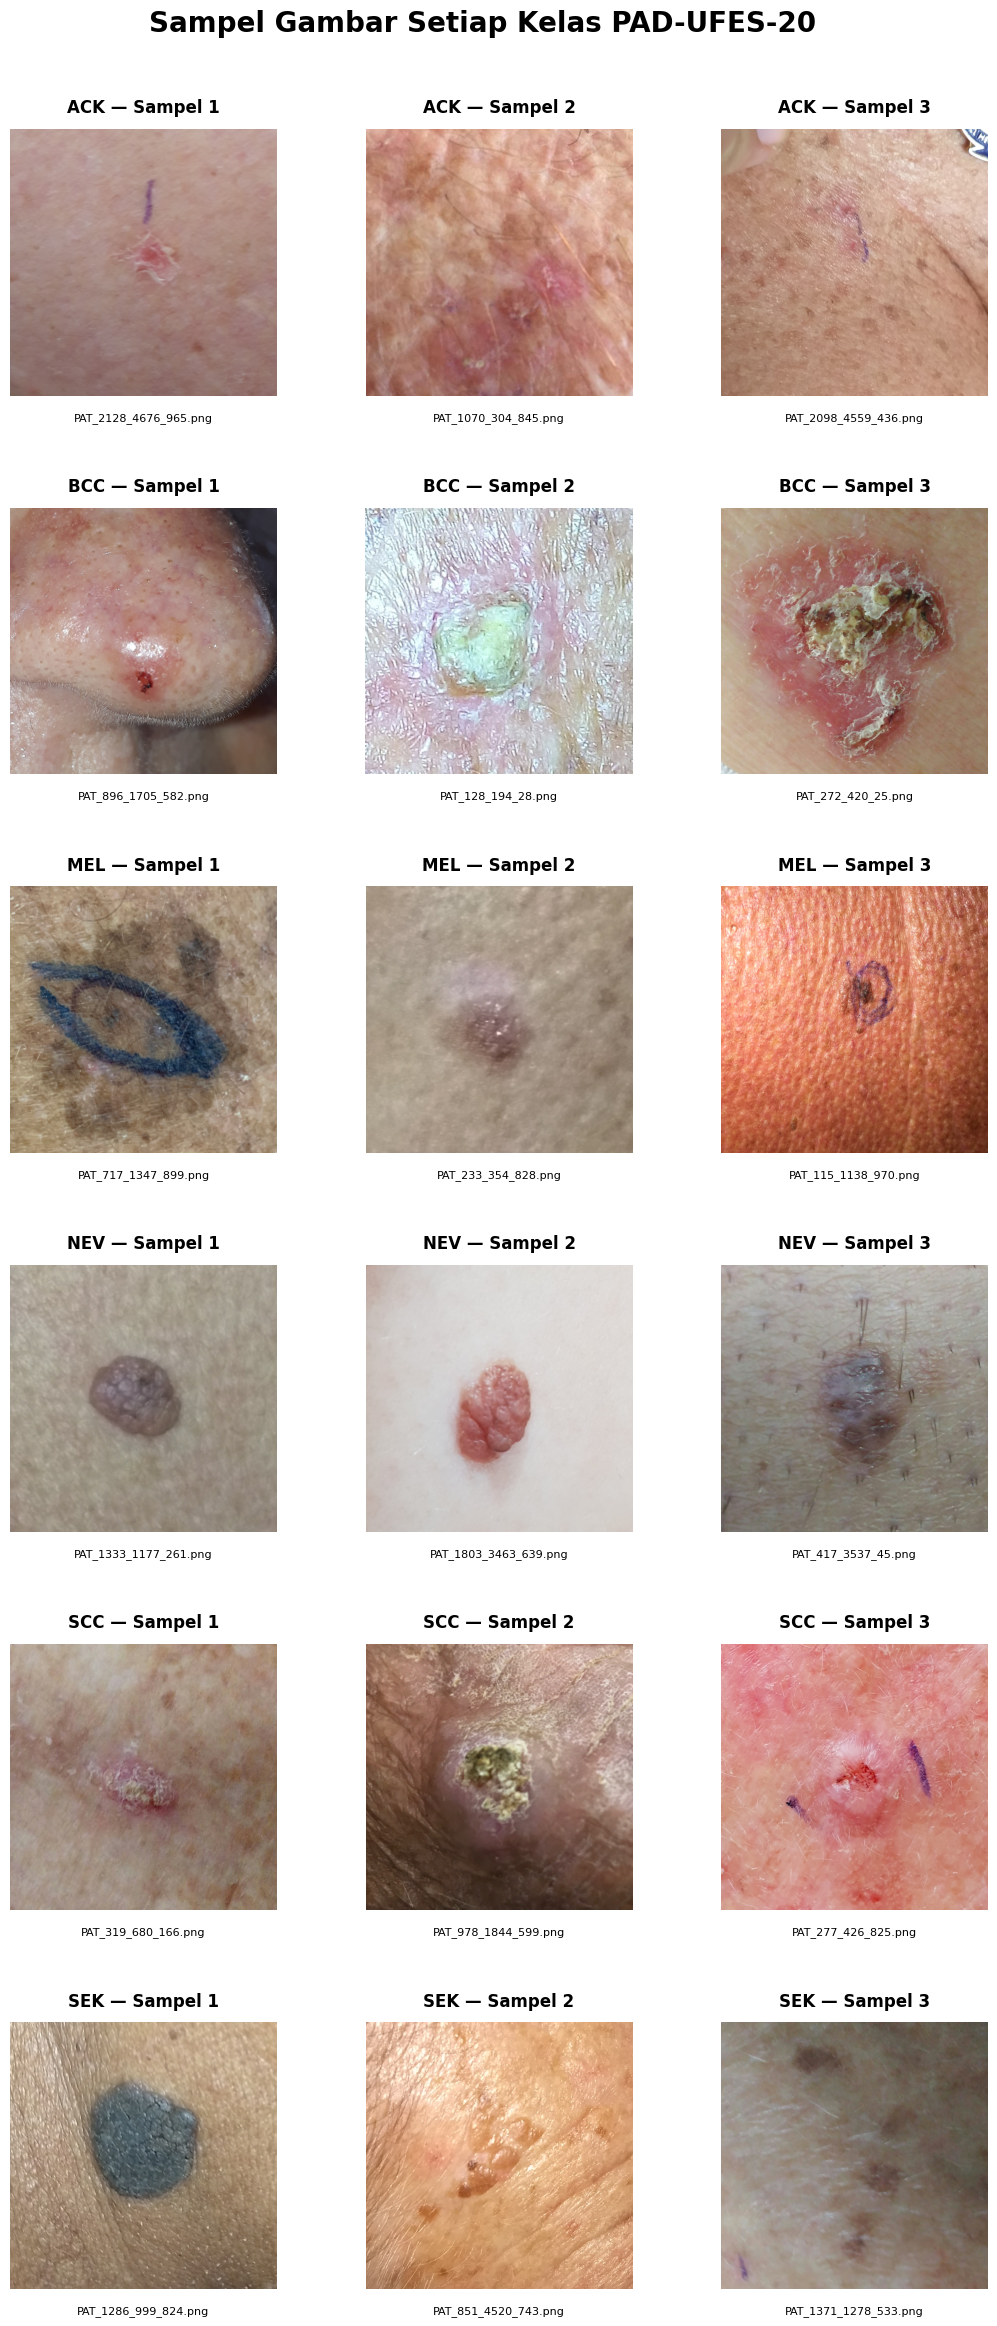

Visualisasi berhasil disimpan:
/content/drive/MyDrive/LesioScan-AI/experiments/eda/figures/sample_images_per_class.png


In [31]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# ==========================================
# 1. KONFIGURASI
# ==========================================

DATASET_DIR = Path(
    "/content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/LesioScan-AI/experiments/eda/figures"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

classes = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]

# ==========================================
# 2. CARI GAMBAR DI GOOGLE DRIVE
# ==========================================

image_paths = {}

for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".jpg", ".jpeg", ".png"
    }:
        if path.name in image_paths:
            raise ValueError(f"Duplikasi nama file: {path.name}")

        image_paths[path.name] = path

print("Total gambar ditemukan:", len(image_paths))

# ==========================================
# 3. BUAT VISUALISASI
# ==========================================

fig, axes = plt.subplots(
    nrows=6,
    ncols=3,
    figsize=(13, 24)
)

for i, cls in enumerate(classes):

    class_df = df[df["diagnostic"] == cls]

    available = class_df[
        class_df["img_id"].astype(str).isin(image_paths)
    ]

    samples = available.sample(
        n=min(3, len(available)),
        random_state=42
    )

    for j in range(3):

        ax = axes[i, j]
        ax.axis("off")

        if j >= len(samples):
            continue

        row = samples.iloc[j]
        path = image_paths[str(row["img_id"])]

        with Image.open(path) as im:
            ax.imshow(im.convert("RGB"))

        # Judul pendek di atas gambar
        ax.set_title(
            f"{cls} — Sampel {j + 1}",
            fontsize=12,
            fontweight="bold",
            pad=12
        )

        # Nama file di bawah gambar
        ax.text(
            0.5,
            -0.06,
            path.name,
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=8
        )

# ==========================================
# 4. ATUR SPASI
# ==========================================

fig.suptitle(
    "Sampel Gambar Setiap Kelas PAD-UFES-20",
    fontsize=20,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    top=0.94,
    bottom=0.04,
    hspace=0.42,
    wspace=0.20
)

# ==========================================
# 5. SIMPAN KE GOOGLE DRIVE
# ==========================================

output_path = OUTPUT_DIR / "sample_images_per_class.png"

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Visualisasi berhasil disimpan:")
print(output_path)

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from IPython.display import display

# Dataset asli
DATASET_DIR = Path(
    "/content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20"
)

# Tempat menyimpan hasil EDA
EDA_DIR = Path(
    "/content/drive/MyDrive/LesioScan-AI/experiments/eda"
)

FIGURES_DIR = EDA_DIR / "figures"
TABLES_DIR = EDA_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Gunakan dataframe yang sudah ada
assert "df" in globals(), "Variabel df belum tersedia."
assert {"img_id", "patient_id", "diagnostic"}.issubset(df.columns)

print("Jumlah data:", len(df))
print("Jumlah pasien:", df["patient_id"].nunique())
print("Lokasi output:", EDA_DIR)

Jumlah data: 2298
Jumlah pasien: 1373
Lokasi output: /content/drive/MyDrive/LesioScan-AI/experiments/eda


In [40]:
class_counts = (
    df["diagnostic"]
    .value_counts()
    .sort_values(ascending=False)
)

total_images = class_counts.sum()

class_analysis = pd.DataFrame({
    "Kelas": class_counts.index,
    "Jumlah Gambar": class_counts.values,
    "Persentase (%)": (
        class_counts.values / total_images * 100
    ).round(2),
    "Rasio terhadap MEL": (
        class_counts.values / class_counts.get("MEL", 1)
    ).round(2)
})

display(class_analysis)

class_analysis.to_csv(
    TABLES_DIR / "class_imbalance_analysis.csv",
    index=False
)

print(
    "Imbalance Ratio:",
    round(class_counts.max() / class_counts.min(), 2)
)

,Kelas,Jumlah Gambar,Persentase (%),Rasio terhadap MEL
0,BCC,845,36.77,16.25
1,ACK,730,31.77,14.04
2,NEV,244,10.62,4.69
3,SEK,235,10.23,4.52
4,SCC,192,8.36,3.69
5,MEL,52,2.26,1.00


Imbalance Ratio: 16.25


Usia minimum: 6
Usia maksimum: 94
Usia rata-rata: 60.46
Median usia: 62.0
Data usia kosong: 0


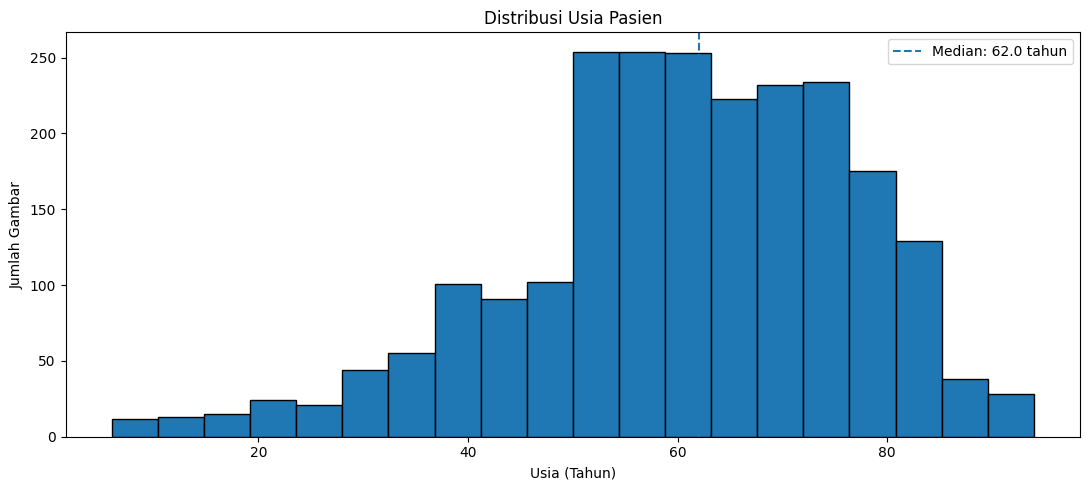

In [42]:
age = pd.to_numeric(df["age"], errors="coerce")

print("Usia minimum:", age.min())
print("Usia maksimum:", age.max())
print("Usia rata-rata:", round(age.mean(), 2))
print("Median usia:", age.median())
print("Data usia kosong:", age.isna().sum())

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    age.dropna(),
    bins=20,
    edgecolor="black"
)

ax.axvline(
    age.median(),
    linestyle="--",
    label=f"Median: {age.median():.1f} tahun"
)

ax.set_title("Distribusi Usia Pasien")
ax.set_xlabel("Usia (Tahun)")
ax.set_ylabel("Jumlah Gambar")

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "age_distribution.png",
    dpi=200
)

plt.show()

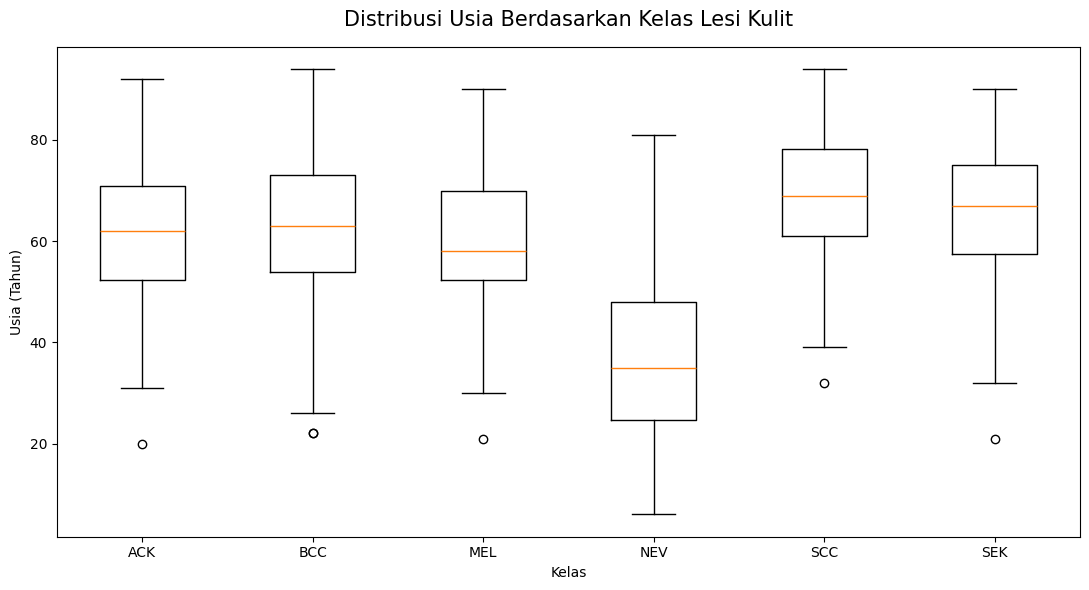

In [43]:
age_df = df[["diagnostic", "age"]].copy()

age_df["age"] = pd.to_numeric(
    age_df["age"],
    errors="coerce"
)

age_df = age_df.dropna()

classes = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]

age_groups = [
    age_df.loc[
        age_df["diagnostic"] == cls,
        "age"
    ].values
    for cls in classes
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.boxplot(
    age_groups,
    tick_labels=classes,
    showfliers=True
)

ax.set_title(
    "Distribusi Usia Berdasarkan Kelas Lesi Kulit",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Kelas")
ax.set_ylabel("Usia (Tahun)")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "age_by_class.png",
    dpi=200
)

plt.show()

gender,FEMALE,MALE,Tidak diketahui
diagnostic,,,
ACK,153,130,447
BCC,406,439,0
MEL,28,24,0
NEV,49,26,169
SCC,90,102,0
SEK,27,20,188


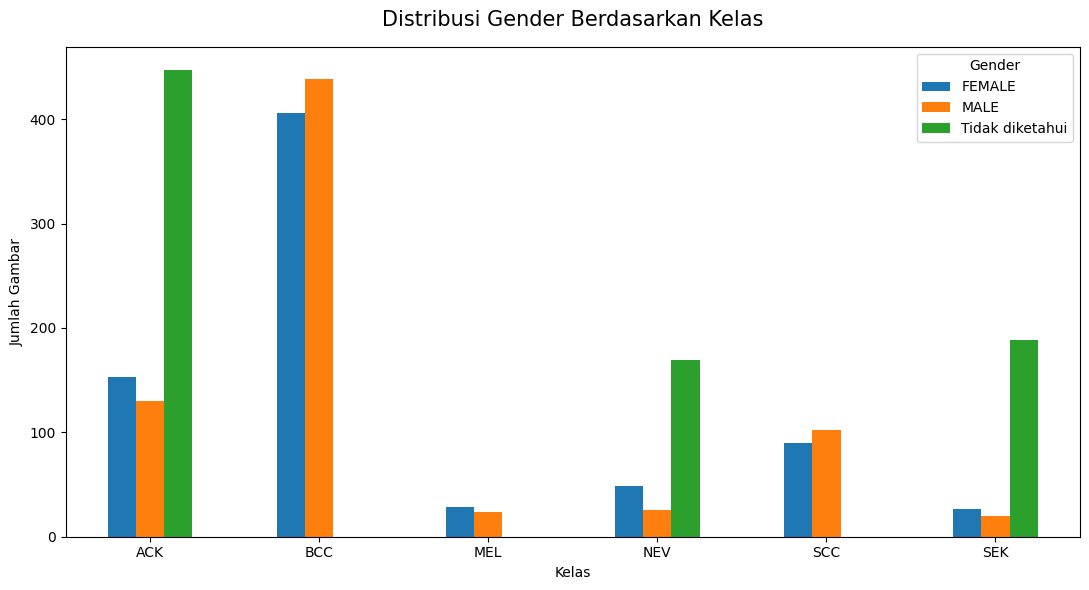

In [44]:
gender_df = pd.crosstab(
    df["diagnostic"],
    df["gender"].fillna("Tidak diketahui")
)

display(gender_df)

ax = gender_df.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title(
    "Distribusi Gender Berdasarkan Kelas",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah Gambar")

plt.xticks(rotation=0)
plt.legend(title="Gender")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "gender_distribution.png",
    dpi=200
)

plt.show()

gender_df.to_csv(
    TABLES_DIR / "gender_distribution.csv"
)

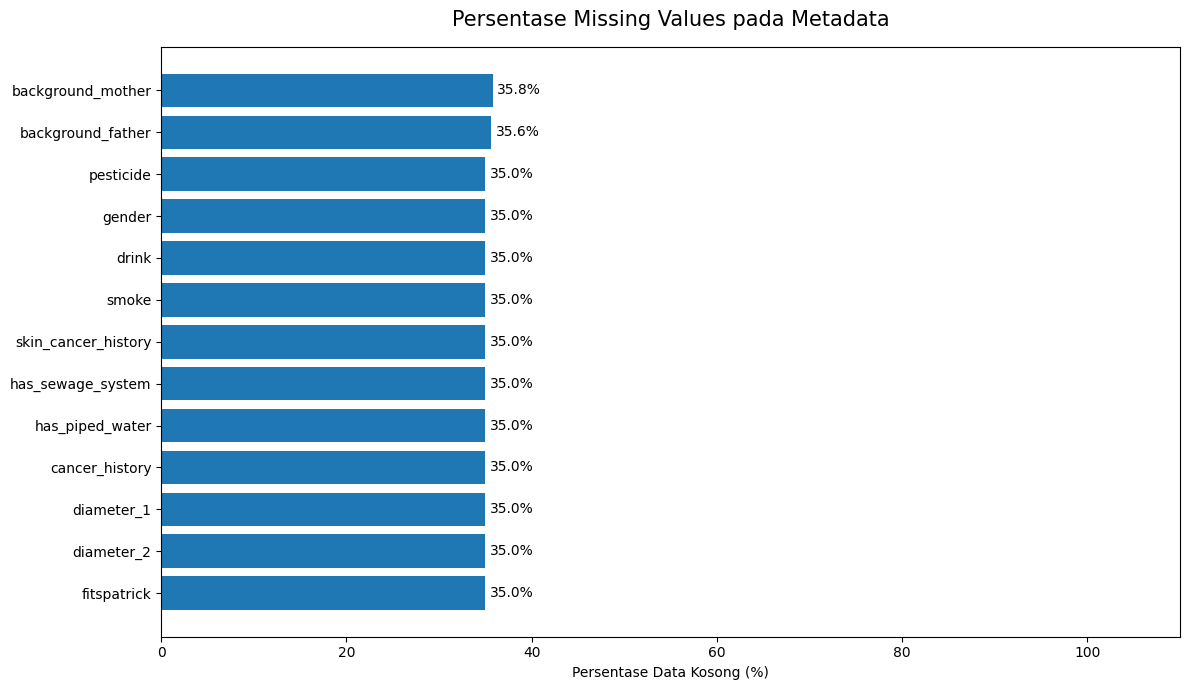

In [45]:
missing_percentage = (
    df.isna().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[
    missing_percentage > 0
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    missing_percentage.index,
    missing_percentage.values
)

ax.invert_yaxis()

for bar in bars:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

ax.set_title(
    "Persentase Missing Values pada Metadata",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Persentase Data Kosong (%)")
ax.set_xlim(0, 110)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "missing_values_percentage.png",
    dpi=200
)

plt.show()

missing_percentage.to_csv(
    TABLES_DIR / "missing_values_percentage.csv",
    header=["persentase"]
)

In [47]:
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

image_info = []
unreadable_images = []

# Gunakan image_paths dari cell sebelumnya
assert "image_paths" in globals(), (
    "Jalankan cell pemetaan lokasi gambar terlebih dahulu."
)

print(f"Total gambar yang diperiksa: {len(image_paths)}")

for name, path in tqdm(
    image_paths.items(),
    total=len(image_paths),
    desc="Menganalisis resolusi gambar"
):
    try:
        with Image.open(path) as im:
            width, height = im.size

        image_info.append({
            "img_id": name,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "megapixels": width * height / 1_000_000
        })

    except (OSError, ValueError) as error:
        unreadable_images.append({
            "img_id": name,
            "error": str(error)
        })

image_df = pd.DataFrame(image_info)

print("Gambar berhasil dibaca:", len(image_df))
print("Gambar gagal dibaca:", len(unreadable_images))

display(image_df.describe())

image_df.to_csv(
    TABLES_DIR / "image_resolution.csv",
    index=False
)

pd.DataFrame(
    unreadable_images,
    columns=["img_id", "error"]
).to_csv(
    TABLES_DIR / "unreadable_images.csv",
    index=False
)

Total gambar yang diperiksa: 2298


Menganalisis resolusi gambar:   0%|          | 0/2298 [00:00<?, ?it/s]

Gambar berhasil dibaca: 2298
Gambar gagal dibaca: 0


,width,height,aspect_ratio,megapixels
count,2298.000000,2298.000000,2298.000000,2298.000000
mean,933.679721,933.605309,1.000189,1.157389
std,534.598513,534.668475,0.007153,1.380141
min,147.000000,147.000000,0.888446,0.021609
25%,528.000000,527.250000,1.000000,0.278784
50%,779.500000,779.500000,1.000000,0.607621
75%,1219.250000,1218.750000,1.000000,1.485961
max,3474.000000,3476.000000,1.156757,12.075624


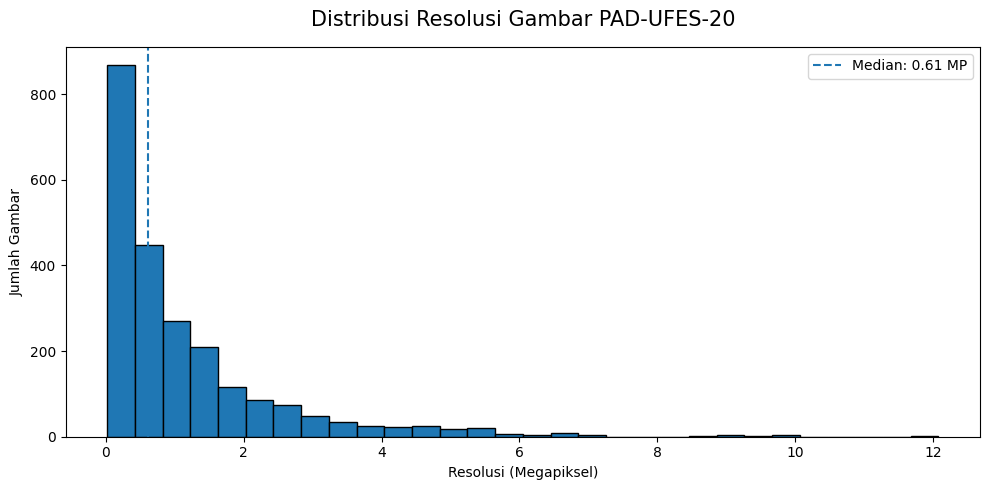

In [48]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    image_df["megapixels"],
    bins=30,
    edgecolor="black"
)

ax.axvline(
    image_df["megapixels"].median(),
    linestyle="--",
    label=f"Median: {image_df['megapixels'].median():.2f} MP"
)

ax.set_title(
    "Distribusi Resolusi Gambar PAD-UFES-20",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Resolusi (Megapiksel)")
ax.set_ylabel("Jumlah Gambar")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "image_megapixels_distribution.png",
    dpi=200
)

plt.show()

# SHUFFLENETV2, Pakai 224x224

In [49]:
low_resolution = image_df[
    (image_df["width"] < 224) |
    (image_df["height"] < 224)
]

print("Jumlah gambar dengan dimensi di bawah 224 px:", len(low_resolution))

display(low_resolution.head(10))

Jumlah gambar dengan dimensi di bawah 224 px: 15


,img_id,width,height,aspect_ratio,megapixels
1,PAT_100_393_898.png,221,221,1.0,0.048841
74,PAT_151_227_63.png,215,215,1.0,0.046225
118,PAT_172_266_950.png,222,222,1.0,0.049284
172,PAT_205_311_255.png,147,147,1.0,0.021609
416,PAT_338_709_306.png,167,167,1.0,0.027889
759,PAT_539_1023_878.png,189,189,1.0,0.035721
832,PAT_59_46_537.png,187,187,1.0,0.034969
855,PAT_72_110_647.png,189,189,1.0,0.035721
870,PAT_82_125_525.png,167,167,1.0,0.027889
874,PAT_84_128_233.png,193,193,1.0,0.037249


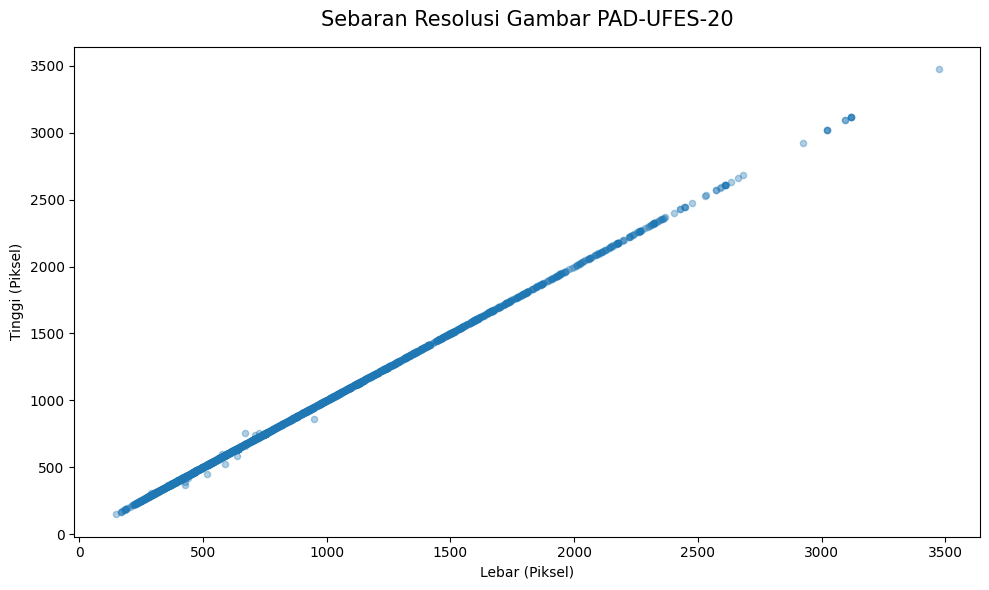

In [50]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    image_df["width"],
    image_df["height"],
    alpha=0.35,
    s=20
)

ax.set_title(
    "Sebaran Resolusi Gambar PAD-UFES-20",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Lebar (Piksel)")
ax.set_ylabel("Tinggi (Piksel)")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "image_resolution_scatter.png",
    dpi=200
)

plt.show()

## Persiapan Lingkungan Data Cleaning

Tahap ini menyiapkan lokasi dataset, direktori penyimpanan laporan, dan salinan metadata.

Dataset asli tetap berada di Google Drive. Proses cleaning dilakukan pada salinan DataFrame sehingga tidak mengubah file sumber.

**Input:** `metadata.csv` PAD-UFES-20.

**Output:** DataFrame kerja `clean_df` dan direktori laporan cleaning.

In [51]:
import json
import hashlib
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from IPython.display import display

# ==========================================
# KONFIGURASI LESIOSCAN
# ==========================================

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/LesioScan-AI"
)

DATASET_DIR = DRIVE_ROOT / "datasets" / "PAD-UFES-20"

CLEANING_DIR = DRIVE_ROOT / "experiments" / "cleaning"
TABLES_DIR = CLEANING_DIR / "tables"

CLEANING_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

METADATA_SOURCE = DATASET_DIR / "metadata.csv"

if not METADATA_SOURCE.is_file():
    raise FileNotFoundError(
        f"Metadata tidak ditemukan: {METADATA_SOURCE}"
    )

# Baca ulang metadata asli agar tidak bergantung
# pada perubahan variabel df dari EDA.
df_raw = pd.read_csv(METADATA_SOURCE)

clean_df = df_raw.copy()

print("=" * 55)
print("LESIOSCAN — DATA CLEANING")
print("=" * 55)

print("Jumlah baris metadata:", len(clean_df))
print("Jumlah kolom:", len(clean_df.columns))
print("Lokasi dataset:", DATASET_DIR)
print("Lokasi laporan:", CLEANING_DIR)

display(clean_df.head())

LESIOSCAN — DATA CLEANING
Jumlah baris metadata: 2298
Jumlah kolom: 26
Lokasi dataset: /content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20
Lokasi laporan: /content/drive/MyDrive/LesioScan-AI/experiments/cleaning


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True


## 6.2 Standarisasi Metadata

### Tujuan

Menyeragamkan format metadata untuk mengurangi kesalahan akibat inkonsistensi penulisan.


In [52]:
# ==========================================
# STANDARISASI METADATA
# ==========================================

clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
)

if clean_df.columns.duplicated().any():
    raise ValueError(
        "Terdapat nama kolom duplikat setelah standarisasi."
    )

REQUIRED_COLUMNS = [
    "img_id",
    "patient_id",
    "diagnostic"
]

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in clean_df.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom wajib tidak tersedia: {missing_columns}"
    )

for col in REQUIRED_COLUMNS:
    clean_df[col] = (
        clean_df[col]
        .astype("string")
        .str.strip()
    )

    clean_df[col] = clean_df[col].replace(
        {
            "": pd.NA,
            "nan": pd.NA,
            "None": pd.NA,
            "null": pd.NA
        }
    )

clean_df["diagnostic"] = (
    clean_df["diagnostic"]
    .str.upper()
)

print("✅ Standarisasi metadata selesai.")

display(
    clean_df[REQUIRED_COLUMNS].head()
)

✅ Standarisasi metadata selesai.


,img_id,patient_id,diagnostic
0,PAT_1516_1765_530.png,PAT_1516,NEV
1,PAT_46_881_939.png,PAT_46,BCC
2,PAT_1545_1867_547.png,PAT_1545,ACK
3,PAT_1989_4061_934.png,PAT_1989,ACK
4,PAT_684_1302_588.png,PAT_684,BCC


## 6.3 Pemeriksaan dan Penanganan Missing Values

### Tujuan

Mengidentifikasi metadata yang kehilangan informasi penting untuk klasifikasi gambar.

### Strategi

Missing values dibagi menjadi dua kategori:

**A. Metadata wajib**

- `img_id`
- `patient_id`
- `diagnostic`

Baris yang tidak memiliki salah satu informasi wajib akan dikarantina.


In [53]:
# ==========================================
# MISSING VALUES ANALYSIS
# ==========================================

missing_summary = pd.DataFrame({
    "kolom": clean_df.columns,
    "jumlah_kosong": clean_df.isna().sum().values,
    "persentase_kosong": (
        clean_df.isna().mean().values * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "persentase_kosong",
    ascending=False
)

display(missing_summary)

missing_summary.to_csv(
    TABLES_DIR / "missing_values_summary.csv",
    index=False
)

# Periksa kolom wajib
required_missing_mask = (
    clean_df[REQUIRED_COLUMNS]
    .isna()
    .any(axis=1)
)

required_missing_df = clean_df.loc[
    required_missing_mask
].copy()

print(
    "Baris dengan metadata wajib kosong:",
    len(required_missing_df)
)

display(
    required_missing_df[
        REQUIRED_COLUMNS
    ].head(10)
)

,kolom,jumlah_kosong,persentase_kosong
5,background_mother,822,35.77
4,background_father,818,35.60
7,pesticide,804,34.99
8,gender,804,34.99
3,drink,804,34.99
2,smoke,804,34.99
9,skin_cancer_history,804,34.99
12,has_sewage_system,804,34.99
11,has_piped_water,804,34.99
10,cancer_history,804,34.99


Baris dengan metadata wajib kosong: 0


,img_id,patient_id,diagnostic


## 6.4 Validasi Label Diagnosis

### Tujuan

Memastikan setiap label diagnosis termasuk salah satu dari enam kelas yang digunakan LesioScan.

In [54]:
# ==========================================
# VALIDASI LABEL
# ==========================================

VALID_LABELS = {
    "ACK",
    "BCC",
    "MEL",
    "NEV",
    "SCC",
    "SEK"
}

invalid_label_mask = (
    clean_df["diagnostic"].notna()
    & ~clean_df["diagnostic"].isin(VALID_LABELS)
)

invalid_label_df = clean_df.loc[
    invalid_label_mask
].copy()

print(
    "Jumlah label tidak valid:",
    len(invalid_label_df)
)

display(
    invalid_label_df[
        REQUIRED_COLUMNS
    ].head(10)
)

print("\nDistribusi label:")

display(
    clean_df["diagnostic"]
    .value_counts(dropna=False)
    .to_frame("jumlah")
)

Jumlah label tidak valid: 0


,img_id,patient_id,diagnostic



Distribusi label:


,jumlah
diagnostic,
BCC,845
ACK,730
NEV,244
SEK,235
SCC,192
MEL,52


## 6.5 Pemeriksaan Duplikasi Metadata

### Tujuan

Mengidentifikasi data yang tercatat berulang dan berpotensi memengaruhi proses training maupun evaluasi.

### Pemeriksaan

1. Duplikasi seluruh baris metadata.
2. Duplikasi `img_id`.
3. Konflik metadata pada `img_id` yang sama.

### Catatan

Gambar berbeda dari pasien atau lesi yang sama tidak otomatis dianggap duplikat.

Duplikasi identitas gambar akan dicatat untuk ditinjau sebelum data digunakan.

In [55]:
# ==========================================
# DUPLICATE DETECTION
# ==========================================

duplicate_rows_mask = clean_df.duplicated(
    keep=False
)

duplicate_id_mask = (
    clean_df["img_id"].notna()
    & clean_df["img_id"].duplicated(keep=False)
)

duplicate_rows_df = clean_df.loc[
    duplicate_rows_mask
].copy()

duplicate_ids_df = clean_df.loc[
    duplicate_id_mask
].copy()

print("Baris identik:", len(duplicate_rows_df))
print("Baris dengan img_id berulang:", len(duplicate_ids_df))

display(
    duplicate_ids_df[
        REQUIRED_COLUMNS
    ].head(10)
)

duplicate_ids_df.to_csv(
    TABLES_DIR / "duplicate_image_ids.csv",
    index=False
)

Baris identik: 0
Baris dengan img_id berulang: 0


,img_id,patient_id,diagnostic


## 6.6 Pemeriksaan Konsistensi Identitas Pasien

### Tujuan

Memastikan informasi identitas pasien dan lesi digunakan secara konsisten.

Pemeriksaan ini penting karena LesioScan menggunakan Patient-Level Splitting untuk mengurangi risiko data leakage.

### Pemeriksaan

- Identitas pasien kosong.
- Identitas gambar berulang dengan pasien berbeda.
- Identitas lesi yang tercatat pada lebih dari satu pasien, apabila kolom `lesion_id` tersedia.

### Catatan

Satu pasien boleh mempunyai beberapa gambar atau beberapa lesi.

Identitas lesi yang berulang perlu diperiksa berdasarkan aturan penomoran dataset sebelum dinyatakan sebagai konflik.

In [56]:
# ==========================================
# PATIENT CONSISTENCY CHECK
# ==========================================

patient_conflicts = pd.DataFrame()

if clean_df["img_id"].notna().any():

    patient_counts = (
        clean_df.dropna(subset=["img_id"])
        .groupby("img_id")["patient_id"]
        .nunique(dropna=False)
    )

    conflicting_ids = patient_counts[
        patient_counts > 1
    ].index

    patient_conflicts = clean_df[
        clean_df["img_id"].isin(conflicting_ids)
    ].copy()

print(
    "Baris dengan konflik pasien per img_id:",
    len(patient_conflicts)
)

display(
    patient_conflicts[
        REQUIRED_COLUMNS
    ].head(10)
)

if "lesion_id" in clean_df.columns:

    lesion_counts = (
        clean_df.dropna(subset=["lesion_id"])
        .groupby("lesion_id")["patient_id"]
        .nunique(dropna=False)
    )

    print(
        "Lesion ID digunakan oleh lebih dari satu pasien:",
        int((lesion_counts > 1).sum())
    )

Baris dengan konflik pasien per img_id: 0


,img_id,patient_id,diagnostic


Lesion ID digunakan oleh lebih dari satu pasien: 250


## 6.7 Pemetaan Lokasi File Gambar

### Tujuan

Menghubungkan nilai `img_id` dengan lokasi file gambar asli di Google Drive.

### Kondisi Dataset

File PAD-UFES-20 disimpan dalam beberapa subfolder, seperti `imgs_part_1` dan `imgs_part_2`.

Program akan mencari gambar di seluruh subfolder dan membuat pemetaan nama file ke lokasi sebenarnya.

### Output

Dictionary `image_paths` yang digunakan untuk memvalidasi keberadaan gambar.

**Catatan:** Tahap ini tidak menyalin dataset 3 GB ke Google Colab.

In [57]:
# ==========================================
# IMAGE PATH INDEXING
# ==========================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png"
}

image_paths = {}
duplicate_filenames = []

for path in DATASET_DIR.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    if path.name in image_paths:
        duplicate_filenames.append({
            "filename": path.name,
            "first_path": str(image_paths[path.name]),
            "second_path": str(path)
        })
        continue

    image_paths[path.name] = path

print("Jumlah file gambar:", len(image_paths))
print("Nama file duplikat:", len(duplicate_filenames))

pd.DataFrame(
    duplicate_filenames,
    columns=["filename", "first_path", "second_path"]
).to_csv(
    TABLES_DIR / "duplicate_filenames.csv",
    index=False
)

Jumlah file gambar: 2298
Nama file duplikat: 0


## 6.8 Pemeriksaan Gambar Tidak Ditemukan

### Tujuan

Memastikan seluruh `img_id` yang tercatat dalam metadata memiliki file gambar yang sesuai.

### Proses

Membandingkan `img_id` dengan indeks lokasi gambar yang telah dibuat.

### Strategi

Gambar yang tidak ditemukan akan dicatat untuk ditinjau. Baris terkait hanya dikeluarkan dari dataset kerja apabila ketidaktersediaannya telah dikonfirmasi.

### Output

`missing_images.csv`

In [58]:
# ==========================================
# MISSING IMAGE CHECK
# ==========================================

missing_image_mask = (
    clean_df["img_id"].notna()
    & ~clean_df["img_id"].isin(image_paths)
)

missing_images_df = clean_df.loc[
    missing_image_mask
].copy()

print("Jumlah gambar tidak ditemukan:", len(missing_images_df))

display(
    missing_images_df[
        REQUIRED_COLUMNS
    ].head(10)
)

missing_images_df.to_csv(
    TABLES_DIR / "missing_images.csv",
    index=False
)

Jumlah gambar tidak ditemukan: 0


,img_id,patient_id,diagnostic


## 6.9 Pemeriksaan Integritas File Gambar

### Tujuan

Memastikan file gambar dapat dibuka dan didekode menggunakan Pillow.

### Pemeriksaan

1. Struktur file gambar.
2. Kemampuan decoding piksel.
3. Dimensi gambar.
4. Format gambar.

### Output

- `image_integrity.csv`
- `corrupted_images.csv`

### Perhatian

Pemeriksaan dilakukan pada seluruh gambar dan dapat memerlukan waktu cukup lama karena file berada di Google Drive.

Hasilnya akan disimpan agar tidak perlu mengulang pemeriksaan pada sesi berikutnya.

In [59]:
# ==========================================
# IMAGE INTEGRITY CHECK
# ==========================================

IMAGE_INTEGRITY_PATH = (
    TABLES_DIR / "image_integrity.csv"
)

CORRUPTED_PATH = (
    TABLES_DIR / "corrupted_images.csv"
)

RUN_IMAGE_CHECK = not IMAGE_INTEGRITY_PATH.exists()

if RUN_IMAGE_CHECK:

    integrity_records = []

    for name, path in tqdm(
        image_paths.items(),
        total=len(image_paths),
        desc="Memeriksa integritas gambar"
    ):

        record = {
            "img_id": name,
            "valid": False,
            "width": None,
            "height": None,
            "format": None,
            "error": ""
        }

        try:
            # Pemeriksaan struktur file
            with Image.open(path) as im:
                im.verify()

            # Buka ulang untuk pemeriksaan decoding
            with Image.open(path) as im:
                im.load()

                record["width"] = im.width
                record["height"] = im.height
                record["format"] = im.format

            record["valid"] = True

        except (OSError, ValueError, SyntaxError) as error:
            record["error"] = str(error)

        integrity_records.append(record)

    integrity_df = pd.DataFrame(integrity_records)

    integrity_df.to_csv(
        IMAGE_INTEGRITY_PATH,
        index=False
    )

else:
    print("Menggunakan hasil pemeriksaan sebelumnya.")
    integrity_df = pd.read_csv(IMAGE_INTEGRITY_PATH)

# Hindari asumsi bahwa data CSV Boolean selalu
# dimuat dalam tipe yang sama.
integrity_df["valid"] = (
    integrity_df["valid"]
    .astype("string")
    .str.lower()
    .eq("true")
)

corrupted_df = integrity_df[
    ~integrity_df["valid"]
].copy()

corrupted_df.to_csv(
    CORRUPTED_PATH,
    index=False
)

print("Total diperiksa:", len(integrity_df))
print("Gambar valid:", int(integrity_df["valid"].sum()))
print("Gambar bermasalah:", len(corrupted_df))

display(corrupted_df.head(10))

Memeriksa integritas gambar:   0%|          | 0/2298 [00:00<?, ?it/s]

Total diperiksa: 2298
Gambar valid: 2298
Gambar bermasalah: 0


,img_id,valid,width,height,format,error


## 6.10 Pemeriksaan Resolusi Gambar

### Tujuan

Mengidentifikasi gambar dengan dimensi yang lebih kecil dari ukuran input awal model, yaitu 224 × 224 piksel.

### Strategi

Gambar beresolusi rendah hanya diberi tanda untuk dianalisis.

Gambar tidak otomatis dihapus karena resolusi kecil tidak selalu berarti gambar tidak dapat digunakan.

### Output

`low_resolution_images.csv`

In [60]:
# ==========================================
# LOW RESOLUTION CHECK
# ==========================================

valid_integrity = integrity_df[
    integrity_df["valid"]
].copy()

low_resolution_df = valid_integrity[
    (valid_integrity["width"] < 224)
    | (valid_integrity["height"] < 224)
].copy()

print(
    "Gambar dengan dimensi di bawah 224 px:",
    len(low_resolution_df)
)

display(low_resolution_df.head(10))

low_resolution_df.to_csv(
    TABLES_DIR / "low_resolution_images.csv",
    index=False
)

Gambar dengan dimensi di bawah 224 px: 15


,img_id,valid,width,height,format,error
1,PAT_100_393_898.png,True,221,221,PNG,
74,PAT_151_227_63.png,True,215,215,PNG,
118,PAT_172_266_950.png,True,222,222,PNG,
172,PAT_205_311_255.png,True,147,147,PNG,
416,PAT_338_709_306.png,True,167,167,PNG,
759,PAT_539_1023_878.png,True,189,189,PNG,
832,PAT_59_46_537.png,True,187,187,PNG,
855,PAT_72_110_647.png,True,189,189,PNG,
870,PAT_82_125_525.png,True,167,167,PNG,
874,PAT_84_128_233.png,True,193,193,PNG,


## 6.11 Pemeriksaan Konsistensi File dan Metadata

### Tujuan

Mencari file gambar yang tersedia di folder dataset tetapi tidak tercantum dalam metadata.

### Proses

Membandingkan daftar file gambar dengan seluruh `img_id`.

### Output

`unreferenced_images.csv`

File yang tidak tercantum dalam metadata tidak digunakan secara otomatis untuk training karena tidak memiliki pasangan label yang terverifikasi.

In [61]:
# ==========================================
# UNREFERENCED IMAGE CHECK
# ==========================================

metadata_image_ids = set(
    clean_df["img_id"].dropna().astype(str)
)

image_file_ids = set(image_paths.keys())

unreferenced_names = sorted(
    image_file_ids - metadata_image_ids
)

unreferenced_df = pd.DataFrame({
    "img_id": unreferenced_names
})

print(
    "File gambar tanpa pasangan metadata:",
    len(unreferenced_df)
)

display(unreferenced_df.head(10))

unreferenced_df.to_csv(
    TABLES_DIR / "unreferenced_images.csv",
    index=False
)

File gambar tanpa pasangan metadata: 0


,img_id


## 6.12 Pembentukan Metadata Bersih dan Data Karantina

### Tujuan

Menggabungkan hasil pemeriksaan menjadi keputusan kelayakan data.

### Kriteria Karantina

- Metadata wajib kosong.
- Label diagnosis tidak valid.
- `img_id` duplikat.
- Identitas pasien bertentangan.
- File gambar tidak ditemukan.
- File gambar gagal diverifikasi atau didekode.

### Data yang Dipertahankan

- Metadata tambahan dengan missing values.
- Gambar beresolusi rendah yang masih valid.
- Beberapa gambar berbeda dari pasien yang sama.

### Output

- `final_clean_df`
- `quarantine_df`
- `cleaning_issues.csv`

Data karantina tetap dicatat dan tidak dihapus permanen.

In [62]:
# ==========================================
# CLEANING DECISION
# ==========================================

issue_records = []

def register_issue(mask, reason):
    for idx in clean_df.index[mask]:
        issue_records.append({
            "row_index": int(idx),
            "img_id": clean_df.at[idx, "img_id"],
            "reason": reason
        })

# 1. Metadata wajib kosong
register_issue(
    required_missing_mask,
    "missing_required_metadata"
)

# 2. Label tidak valid
register_issue(
    invalid_label_mask,
    "invalid_diagnostic"
)

# 3. img_id duplikat
register_issue(
    duplicate_id_mask,
    "duplicate_image_id"
)

# 4. Konflik identitas pasien
register_issue(
    clean_df.index.isin(patient_conflicts.index),
    "patient_identity_conflict"
)

# 5. File gambar tidak ditemukan
register_issue(
    missing_image_mask,
    "missing_image_file"
)

# 6. Gambar bermasalah
corrupted_names = set(
    corrupted_df["img_id"].astype(str)
)

register_issue(
    clean_df["img_id"].isin(corrupted_names),
    "corrupted_image"
)

issues_df = pd.DataFrame(
    issue_records,
    columns=["row_index", "img_id", "reason"]
)

issues_df.to_csv(
    TABLES_DIR / "cleaning_issues.csv",
    index=False
)

# Gabungkan alasan per baris
if len(issues_df) > 0:

    issues_grouped = (
        issues_df.groupby("row_index")["reason"]
        .agg(lambda values: "; ".join(sorted(set(values))))
    )

    clean_df["cleaning_issue"] = (
        clean_df.index.map(issues_grouped)
    )

else:
    clean_df["cleaning_issue"] = pd.NA

quarantine_df = clean_df[
    clean_df["cleaning_issue"].notna()
].copy()

final_clean_df = clean_df[
    clean_df["cleaning_issue"].isna()
].drop(columns=["cleaning_issue"]).copy()

print("=" * 50)
print("HASIL DATA CLEANING")
print("=" * 50)

print("Data awal:", len(df_raw))
print("Data bersih:", len(final_clean_df))
print("Data karantina:", len(quarantine_df))

HASIL DATA CLEANING
Data awal: 2298
Data bersih: 2298
Data karantina: 0


## 6.13 Analisis Distribusi Kelas Setelah Cleaning

### Tujuan

Memeriksa apakah proses cleaning menyebabkan perubahan jumlah gambar pada masing-masing kelas.

### Proses

Membandingkan distribusi kelas sebelum dan sesudah pembersihan.

### Output

Tabel `class_distribution_after_cleaning.csv`.

### Catatan

Jika kelas minoritas kehilangan banyak gambar, dampaknya perlu dianalisis sebelum training.

In [63]:
# ==========================================
# BEFORE VS AFTER CLEANING
# ==========================================

before_counts = (
    clean_df["diagnostic"]
    .value_counts()
)

after_counts = (
    final_clean_df["diagnostic"]
    .value_counts()
)

comparison_df = pd.DataFrame({
    "sebelum": before_counts,
    "sesudah": after_counts
}).fillna(0).astype(int)

comparison_df["berkurang"] = (
    comparison_df["sebelum"]
    - comparison_df["sesudah"]
)

display(comparison_df)

comparison_df.to_csv(
    TABLES_DIR / "class_distribution_after_cleaning.csv"
)

,sebelum,sesudah,berkurang
diagnostic,,,
BCC,845,845,0
ACK,730,730,0
NEV,244,244,0
SEK,235,235,0
SCC,192,192,0
MEL,52,52,0


## 6.14 Validasi Akhir Dataset Bersih

### Tujuan

Memastikan metadata bersih memenuhi persyaratan teknis dasar sebelum Patient-Level Splitting.

### Pemeriksaan

1. Kolom wajib tersedia dan tidak kosong.
2. Identitas gambar unik.
3. Label diagnosis valid.
4. File gambar tersedia.
5. Gambar lolos pemeriksaan integritas.

Jika terdapat masalah, proses dihentikan agar dataset yang belum valid tidak digunakan untuk training.

In [64]:
# ==========================================
# FINAL VALIDATION
# ==========================================

assert len(final_clean_df) > 0, (
    "Dataset bersih kosong."
)

assert not final_clean_df[
    REQUIRED_COLUMNS
].isna().any().any(), (
    "Masih terdapat metadata wajib yang kosong."
)

assert final_clean_df[
    "img_id"
].is_unique, (
    "Masih terdapat img_id duplikat."
)

assert final_clean_df[
    "diagnostic"
].isin(VALID_LABELS).all(), (
    "Masih terdapat label diagnosis tidak valid."
)

assert final_clean_df[
    "img_id"
].isin(image_paths).all(), (
    "Masih terdapat file gambar tidak ditemukan."
)

valid_image_names = set(
    integrity_df.loc[
        integrity_df["valid"],
        "img_id"
    ].astype(str)
)

assert final_clean_df[
    "img_id"
].isin(valid_image_names).all(), (
    "Masih terdapat gambar yang tidak lolos pemeriksaan integritas."
)

print("✅ Validasi akhir dataset bersih berhasil.")
print("Jumlah data valid:", len(final_clean_df))

✅ Validasi akhir dataset bersih berhasil.
Jumlah data valid: 2298


## 6.15 Penyimpanan Hasil Data Cleaning

### Tujuan

Menyimpan metadata bersih, data karantina, dan laporan hasil cleaning ke Google Drive.

### Output Utama

| File | Fungsi |
|---|---|
| `metadata_clean.csv` | Metadata bersih untuk splitting |
| `quarantine.csv` | Data yang perlu ditinjau |
| `cleaning_issues.csv` | Daftar alasan masalah |
| `image_integrity.csv` | Hasil pemeriksaan gambar |
| `cleaning_summary.json` | Ringkasan proses pembersihan |

### Lokasi

`MyDrive/LesioScan-AI/experiments/cleaning/`

Hasil ini menjadi input untuk tahap Patient-Level Splitting.

In [65]:
# ==========================================
# SAVE CLEANING OUTPUTS
# ==========================================

final_clean_df.to_csv(
    CLEANING_DIR / "metadata_clean.csv",
    index=False
)

quarantine_df.to_csv(
    CLEANING_DIR / "quarantine.csv",
    index=False
)

summary = {
    "dataset": "PAD-UFES-20",
    "project": "LesioScan",
    "initial_metadata_rows": int(len(df_raw)),
    "clean_metadata_rows": int(len(final_clean_df)),
    "quarantined_rows": int(len(quarantine_df)),
    "missing_image_rows": int(missing_image_mask.sum()),
    "invalid_label_rows": int(invalid_label_mask.sum()),
    "duplicate_image_id_rows": int(duplicate_id_mask.sum()),
    "corrupted_image_files": int(len(corrupted_df)),
    "low_resolution_files": int(len(low_resolution_df)),
    "valid_classes": sorted(VALID_LABELS)
}

with open(
    CLEANING_DIR / "cleaning_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print("✅ Seluruh hasil cleaning berhasil disimpan.")
print("Lokasi:", CLEANING_DIR)

✅ Seluruh hasil cleaning berhasil disimpan.
Lokasi: /content/drive/MyDrive/LesioScan-AI/experiments/cleaning


## 6.16 Integrasi Metadata Bersih dengan Repository

### Tujuan

Menyiapkan `metadata_clean.csv` agar dapat digunakan oleh script Patient-Level Splitting di repository LesioScan.

### Proses

Menyalin metadata bersih ke direktori kerja:

`/content/lesioscan-ml/data/metadata_clean.csv`

### Catatan

File gambar tetap disimpan di Google Drive. Tidak ada proses penyalinan seluruh gambar.

Pada tahap splitting dan training, lokasi gambar harus sesuai dengan konfigurasi `data.py` dan file YAML proyek.

In [66]:
# ==========================================
# EXPORT CLEAN METADATA TO REPOSITORY
# ==========================================

import shutil

PROJECT_DATA = Path(
    "/content/lesioscan-ml/data"
)

if PROJECT_DATA.parent.is_dir():

    PROJECT_DATA.mkdir(
        parents=True,
        exist_ok=True
    )

    shutil.copy2(
        CLEANING_DIR / "metadata_clean.csv",
        PROJECT_DATA / "metadata_clean.csv"
    )

    print("✅ Metadata bersih tersedia di repository.")

else:
    print(
        "Repository belum tersedia pada runtime ini."
    )

✅ Metadata bersih tersedia di repository.


#**Audit hasil cleaning**

In [67]:
import json
import pandas as pd
from pathlib import Path
from IPython.display import display

CLEANING_DIR = Path(
    "/content/drive/MyDrive/LesioScan-AI/experiments/cleaning"
)

# Baca hasil cleaning
clean_df = pd.read_csv(
    CLEANING_DIR / "metadata_clean.csv"
)

quarantine_df = pd.read_csv(
    CLEANING_DIR / "quarantine.csv"
)

issues_df = pd.read_csv(
    CLEANING_DIR / "tables/cleaning_issues.csv"
)

with open(
    CLEANING_DIR / "cleaning_summary.json",
    encoding="utf-8"
) as f:
    summary = json.load(f)

print("=" * 55)
print("AUDIT HASIL DATA CLEANING — LESIOSCAN")
print("=" * 55)

print("\n1. RINGKASAN")
print("Data awal:", summary["initial_metadata_rows"])
print("Data bersih:", len(clean_df))
print("Data karantina:", len(quarantine_df))

print("\n2. ALASAN KARANTINA")

if not issues_df.empty:
    display(
        issues_df["reason"]
        .value_counts()
        .to_frame("jumlah")
    )
else:
    print("Tidak ada masalah yang tercatat.")

print("\n3. DISTRIBUSI KELAS SETELAH CLEANING")
display(
    clean_df["diagnostic"]
    .value_counts()
    .to_frame("jumlah_gambar")
)

print("\n4. VALIDASI DASAR")

required = ["img_id", "patient_id", "diagnostic"]

assert not clean_df[required].isna().any().any()
assert clean_df["img_id"].is_unique
assert set(clean_df["diagnostic"]) == {
    "ACK", "BCC", "MEL", "NEV", "SCC", "SEK"
}

print("✅ Metadata wajib lengkap")
print("✅ img_id unik")
print("✅ Keenam kelas tersedia")

AUDIT HASIL DATA CLEANING — LESIOSCAN

1. RINGKASAN
Data awal: 2298
Data bersih: 2298
Data karantina: 0

2. ALASAN KARANTINA
Tidak ada masalah yang tercatat.

3. DISTRIBUSI KELAS SETELAH CLEANING


,jumlah_gambar
diagnostic,
BCC,845
ACK,730
NEV,244
SEK,235
SCC,192
MEL,52



4. VALIDASI DASAR
✅ Metadata wajib lengkap
✅ img_id unik
✅ Keenam kelas tersedia


---

# 7. Patient-Level Data Splitting

Membagi dataset PAD-UFES-20 menjadi **Training (70%), Validation (15%), dan Testing (15%)** berdasarkan identitas pasien.

Pembagian mempertimbangkan distribusi enam kelas untuk mengurangi ketidakseimbangan antarkelompok.

**Prinsip:** Pasien yang sama tidak boleh muncul pada lebih dari satu kelompok data.

In [68]:
import pandas as pd
import numpy as np
import json

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display

# ==========================================
# KONFIGURASI
# ==========================================

SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

N_CANDIDATES = 500

CLASSES = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]

DRIVE_ROOT = Path("/content/drive/MyDrive/LesioScan-AI")

CLEAN_METADATA = (
    DRIVE_ROOT / "experiments/cleaning/metadata_clean.csv"
)

SPLIT_DIR = DRIVE_ROOT / "experiments/splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

df_split = pd.read_csv(CLEAN_METADATA)

required = {"img_id", "patient_id", "diagnostic"}
assert required.issubset(df_split.columns)
assert not df_split[list(required)].isna().any().any()
assert df_split["img_id"].is_unique
assert set(df_split["diagnostic"]) == set(CLASSES)

assert np.isclose(
    TRAIN_RATIO + VAL_RATIO + TEST_RATIO, 1.0
)

print("Dataset siap untuk splitting.")
print("Jumlah gambar:", len(df_split))
print("Jumlah pasien:", df_split["patient_id"].nunique())
print("Jumlah kelas:", df_split["diagnostic"].nunique())

Dataset siap untuk splitting.
Jumlah gambar: 2298
Jumlah pasien: 1373
Jumlah kelas: 6


## 7.1 Stratified Patient-Level Splitting

Mencari pembagian dataset yang menjaga **identitas pasien tetap terpisah** sekaligus mempertahankan proporsi kelas sedekat mungkin dengan distribusi aslinya.

Metode menggunakan pencarian beberapa kandidat pembagian berbasis pasien.

**Output:** Pembagian Train, Validation, dan Test.

In [69]:
# ==========================================
# PATIENT-LEVEL SPLIT OPTIMIZATION
# ==========================================

labels = df_split["diagnostic"].to_numpy()
patients = df_split["patient_id"].to_numpy()

N = len(df_split)

overall_distribution = (
    df_split["diagnostic"]
    .value_counts(normalize=True)
    .reindex(CLASSES, fill_value=0)
    .to_numpy()
)

target_ratios = {
    "train": TRAIN_RATIO,
    "val": VAL_RATIO,
    "test": TEST_RATIO
}


def score_split(parts):
    """
    Mengukur kualitas pembagian:
    1. Kedekatan rasio gambar terhadap target.
    2. Kedekatan distribusi kelas antar-split.
    """

    score = 0.0

    for split_name, subset in parts.items():

        if subset.empty:
            return float("inf")

        actual_ratio = len(subset) / N

        ratio_error = abs(
            actual_ratio - target_ratios[split_name]
        )

        class_distribution = (
            subset["diagnostic"]
            .value_counts(normalize=True)
            .reindex(CLASSES, fill_value=0)
            .to_numpy()
        )

        distribution_error = np.abs(
            class_distribution - overall_distribution
        ).mean()

        missing_classes = sum(
            subset["diagnostic"].value_counts()
            .reindex(CLASSES, fill_value=0) == 0
        )

        score += (
            2.0 * ratio_error
            + distribution_error
            + 10.0 * missing_classes
        )

    return score


best_score = float("inf")
best_parts = None

outer_splitter = GroupShuffleSplit(
    n_splits=N_CANDIDATES,
    test_size=TEST_RATIO,
    random_state=SEED
)

for candidate_id, (train_val_idx, test_idx) in enumerate(
    outer_splitter.split(
        df_split,
        y=labels,
        groups=patients
    )
):

    train_val_df = df_split.iloc[train_val_idx]
    test_df = df_split.iloc[test_idx]

    inner_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=VAL_RATIO / (TRAIN_RATIO + VAL_RATIO),
        random_state=SEED + candidate_id
    )

    train_rel, val_rel = next(
        inner_splitter.split(
            train_val_df,
            y=train_val_df["diagnostic"],
            groups=train_val_df["patient_id"]
        )
    )

    parts = {
        "train": train_val_df.iloc[train_rel],
        "val": train_val_df.iloc[val_rel],
        "test": test_df
    }

    score = score_split(parts)

    if score < best_score:
        best_score = score
        best_parts = {
            name: subset.copy()
            for name, subset in parts.items()
        }

if best_parts is None:
    raise RuntimeError("Tidak berhasil menemukan pembagian data.")

print("Pembagian terbaik ditemukan.")
print("Skor:", round(best_score, 6))

for name, subset in best_parts.items():
    print(
        f"{name.upper():5s}: "
        f"{len(subset):4d} gambar, "
        f"{subset['patient_id'].nunique():4d} pasien"
    )

Pembagian terbaik ditemukan.
Skor: 0.026354
TRAIN: 1608 gambar,  961 pasien
VAL  :  339 gambar,  206 pasien
TEST :  351 gambar,  206 pasien


## 7.2 Validasi Data Leakage

Memastikan tidak terdapat pasien maupun gambar yang muncul pada lebih dari satu kelompok data.

Validasi dilakukan sebelum pembagian digunakan untuk training.

In [70]:
# ==========================================
# DATA LEAKAGE VALIDATION
# ==========================================

patient_sets = {
    name: set(part["patient_id"])
    for name, part in best_parts.items()
}

image_sets = {
    name: set(part["img_id"])
    for name, part in best_parts.items()
}

pairs = [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]

for first, second in pairs:

    patient_overlap = (
        patient_sets[first] & patient_sets[second]
    )

    image_overlap = (
        image_sets[first] & image_sets[second]
    )

    print(
        f"{first} vs {second}: "
        f"{len(patient_overlap)} pasien sama, "
        f"{len(image_overlap)} gambar sama"
    )

    assert len(patient_overlap) == 0
    assert len(image_overlap) == 0

all_ids = (
    image_sets["train"]
    | image_sets["val"]
    | image_sets["test"]
)

assert len(all_ids) == len(df_split)

print("\n✅ Tidak ditemukan data leakage berdasarkan patient_id dan img_id.")

train vs val: 0 pasien sama, 0 gambar sama
train vs test: 0 pasien sama, 0 gambar sama
val vs test: 0 pasien sama, 0 gambar sama

✅ Tidak ditemukan data leakage berdasarkan patient_id dan img_id.


## 7.3 Validasi Distribusi Kelas

Memeriksa jumlah dan persentase gambar setiap kelas pada Training, Validation, dan Test Set.

Analisis ini penting karena PAD-UFES-20 memiliki ketidakseimbangan kelas, khususnya MEL.

In [71]:
# ==========================================
# CLASS DISTRIBUTION VALIDATION
# ==========================================

distribution = pd.DataFrame({
    name: subset["diagnostic"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    for name, subset in best_parts.items()
})

distribution["total"] = distribution.sum(axis=1)

display(distribution)

distribution_pct = (
    distribution[["train", "val", "test"]]
    .div(
        distribution[["train", "val", "test"]].sum(axis=0),
        axis=1
    )
    * 100
).round(2)

print("\nPersentase distribusi kelas:")
display(distribution_pct)

assert (
    distribution[["train", "val", "test"]] > 0
).all().all(), (
    "Ada kelas yang tidak terwakili pada salah satu split."
)

print("\n✅ Keenam kelas tersedia pada seluruh split.")

,train,val,test,total
diagnostic,,,,
ACK,504,111,115,730
BCC,591,124,130,845
MEL,37,7,8,52
NEV,177,31,36,244
SCC,130,30,32,192
SEK,169,36,30,235



Persentase distribusi kelas:


,train,val,test
diagnostic,,,
ACK,31.34,32.74,32.76
BCC,36.75,36.58,37.04
MEL,2.30,2.06,2.28
NEV,11.01,9.14,10.26
SCC,8.08,8.85,9.12
SEK,10.51,10.62,8.55



✅ Keenam kelas tersedia pada seluruh split.


## 7.4 Visualisasi Hasil Splitting

Menampilkan perbandingan distribusi kelas dan proporsi dataset pada Training, Validation, dan Test Set.

Grafik disimpan ke Google Drive untuk dokumentasi dan laporan ML.

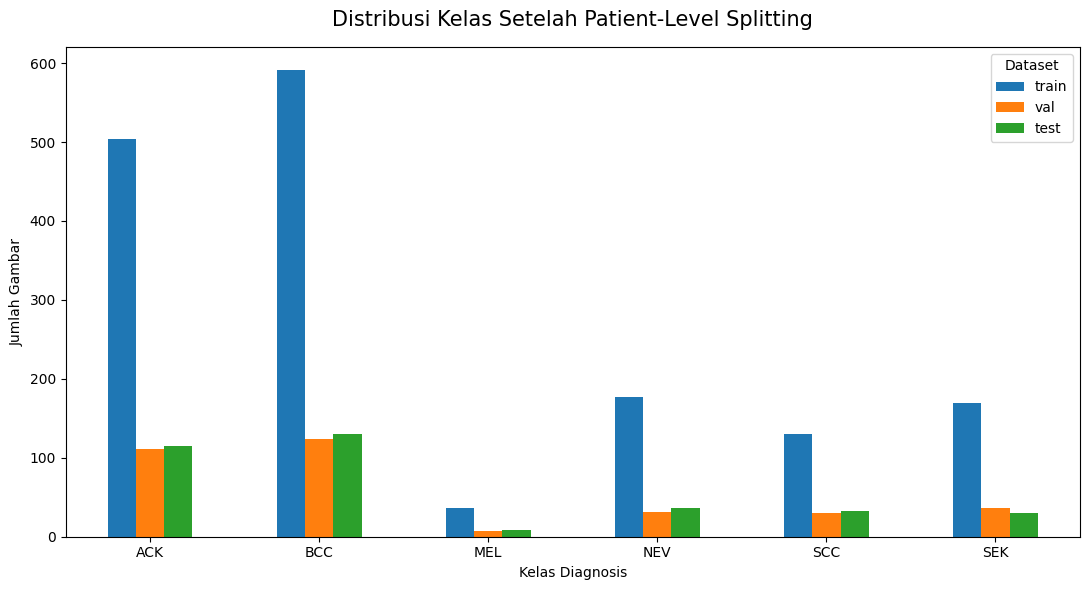

In [72]:
import matplotlib.pyplot as plt

FIGURES_DIR = SPLIT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ax = distribution[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title(
    "Distribusi Kelas Setelah Patient-Level Splitting",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Kelas Diagnosis")
ax.set_ylabel("Jumlah Gambar")

plt.xticks(rotation=0)
plt.legend(title="Dataset")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "split_class_distribution.png",
    dpi=200
)

plt.show()

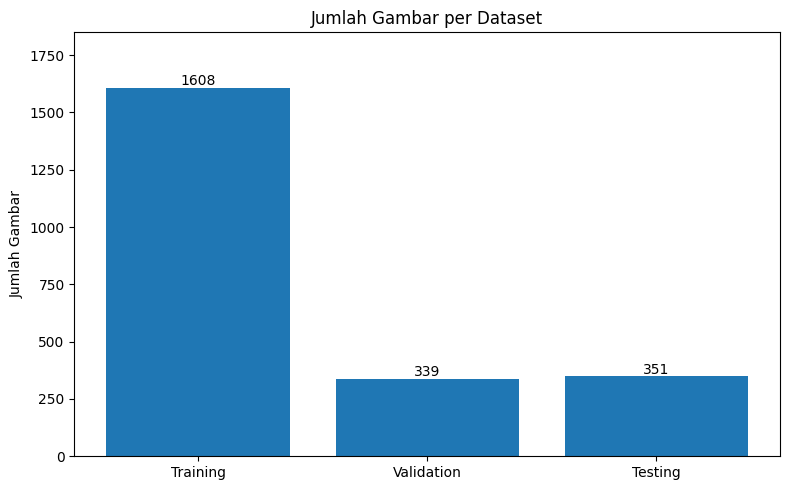

In [73]:
split_sizes = pd.Series({
    name: len(subset)
    for name, subset in best_parts.items()
})

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Training", "Validation", "Testing"],
    split_sizes.values
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        f"{int(bar.get_height())}",
        ha="center"
    )

ax.set_title("Jumlah Gambar per Dataset")
ax.set_ylabel("Jumlah Gambar")
ax.set_ylim(0, split_sizes.max() * 1.15)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "split_sizes.png",
    dpi=200
)

plt.show()

## 7.5 Penyimpanan Hasil Splitting

Menyimpan hasil pembagian dataset ke Google Drive agar dapat digunakan oleh Notebook Model Training.

**Output utama:**
- `split.csv`
- `split_distribution.csv`
- `split_summary.json`

Pembagian yang sama akan digunakan untuk seluruh model benchmark agar perbandingan eksperimen konsisten.

In [74]:
# ==========================================
# SAVE SPLIT RESULTS
# ==========================================

split_frames = []

for name, subset in best_parts.items():

    part = subset.copy()
    part["split"] = name

    split_frames.append(part)

split_df = pd.concat(
    split_frames,
    ignore_index=True
)

# Urutan baris deterministik
split_df = split_df.sort_values(
    "img_id"
).reset_index(drop=True)

# Simpan seluruh metadata dan label split
split_df.to_csv(
    SPLIT_DIR / "split.csv",
    index=False
)

# Simpan distribusi kelas
distribution.to_csv(
    SPLIT_DIR / "split_distribution.csv"
)

summary = {
    "project": "LesioScan",
    "dataset": "PAD-UFES-20",
    "seed": SEED,
    "method": "Patient-level candidate-search splitting",
    "candidates": N_CANDIDATES,
    "best_score": float(best_score),
    "target_ratios": target_ratios,
    "actual_ratios": {
        name: round(len(part) / len(df_split), 4)
        for name, part in best_parts.items()
    },
    "image_counts": {
        name: int(len(part))
        for name, part in best_parts.items()
    },
    "patient_counts": {
        name: int(part["patient_id"].nunique())
        for name, part in best_parts.items()
    }
}

with open(
    SPLIT_DIR / "split_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print("✅ Hasil splitting berhasil disimpan.")
print("Lokasi:", SPLIT_DIR)

display(split_df.head())

✅ Hasil splitting berhasil disimpan.
Lokasi: /content/drive/MyDrive/LesioScan-AI/experiments/splits


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed,split
0,PAT_1000,31,NaN,NaN,NaN,NaN,65,NaN,NaN,NaN,...,SEK,False,False,False,False,False,False,PAT_1000_31_620.png,False,train
1,PAT_1006,53,NaN,NaN,NaN,NaN,63,NaN,NaN,NaN,...,ACK,False,False,False,False,False,False,PAT_1006_53_385.png,False,val
2,PAT_1006,53,NaN,NaN,NaN,NaN,63,NaN,NaN,NaN,...,ACK,False,False,False,False,False,False,PAT_1006_53_716.png,False,val
3,PAT_1008,59,NaN,NaN,NaN,NaN,64,NaN,NaN,NaN,...,SEK,False,True,False,False,False,True,PAT_1008_59_297.png,False,train
4,PAT_100,393,False,False,POMERANIA,POMERANIA,14,False,MALE,False,...,NEV,False,False,False,False,False,False,PAT_100_393_595.png,True,train


## 7.6 Verifikasi Akhir Splitting

Memastikan seluruh file output berhasil disimpan dan siap digunakan oleh notebook pelatihan model.

Setelah verifikasi berhasil, proses Data Preparation dinyatakan selesai.

In [75]:
# ==========================================
# FINAL SPLIT VERIFICATION
# ==========================================

required_outputs = [
    "split.csv",
    "split_distribution.csv",
    "split_summary.json",
    "figures/split_class_distribution.png",
    "figures/split_sizes.png"
]

for name in required_outputs:

    path = SPLIT_DIR / name

    print(
        "✅" if path.is_file() else "❌",
        name
    )

saved_split = pd.read_csv(
    SPLIT_DIR / "split.csv"
)

assert len(saved_split) == len(df_split)
assert saved_split["img_id"].is_unique
assert set(saved_split["split"]) == {
    "train", "val", "test"
}

print("\n✅ Patient-Level Splitting selesai.")
print("Dataset siap untuk Model Training.")

✅ split.csv
✅ split_distribution.csv
✅ split_summary.json
✅ figures/split_class_distribution.png
✅ figures/split_sizes.png

✅ Patient-Level Splitting selesai.
Dataset siap untuk Model Training.


## 7. Kesimpulan EDA — isi setelah ada hasil
- Distribusi kelas: ...
- Kelengkapan data: ...
- Karakteristik pasien/gambar: ...
- Dampak terhadap training set: ...
- Keterbatasan: ...